<a href="https://colab.research.google.com/github/Nihat0311/Machine-Learning/blob/main/Ensamble_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import BaggingClassifier, BaggingRegressor
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor

from sklearn.datasets import make_classification, make_regression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor

In [ ]:
X, y = make_classification(
    n_samples=6000,
    n_features=30,
    n_informative=10,
    n_redundant=10,
    n_clusters_per_class=2,
    flip_y=0.05,
    class_sep=1.0,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

In [ ]:
base_tree=DecisionTreeClassifier(
    random_state=42,
    min_samples_leaf=2,
    max_depth=10
    )
model=BaggingClassifier(
    estimator=base_tree,
    n_estimators=100,
    random_state=42,
    bootstrap=True,
    oob_score=True
)
model.fit(X_train, y_train)

BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=10,
                                                   min_samples_leaf=2,
                                                   random_state=42),
                  n_estimators=100, oob_score=True, random_state=42)

In [ ]:
model.score(X_train, y_train)

0.9655555555555555

In [ ]:
model.score(X_test, y_test)

0.896

In [ ]:
y_pred=model.predict(X_test)
y_proba=model.predict_proba(X_test)[:5]

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.88      0.89       750
           1       0.89      0.91      0.90       750

    accuracy                           0.90      1500
   macro avg       0.90      0.90      0.90      1500
weighted avg       0.90      0.90      0.90      1500



In [ ]:
y_proba

array([[0.18294498, 0.81705502],
       [0.93580479, 0.06419521],
       [0.00977243, 0.99022757],
       [0.82574512, 0.17425488],
       [0.40702754, 0.59297246]])

<Axes: >

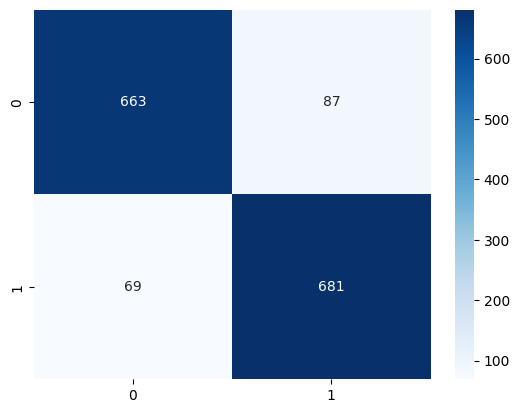

In [ ]:
cm=confusion_matrix(y_test, y_pred)

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')

In [ ]:
base_tree=DecisionTreeClassifier(
    random_state=42,
    min_samples_leaf=2,
    max_depth=10
    )
model=BaggingClassifier(
    estimator=base_tree,
    n_estimators=100,
    random_state=42,
    bootstrap=False

)
model.fit(X_train, y_train)

BaggingClassifier(bootstrap=False,
                  estimator=DecisionTreeClassifier(max_depth=10,
                                                   min_samples_leaf=2,
                                                   random_state=42),
                  n_estimators=100, random_state=42)

In [ ]:
model.score(X_train, y_train),model.score(X_test, y_test)

(0.9393333333333334, 0.8593333333333333)

In [ ]:
y_pred=model.predict(X_test)
y_proba=model.predict_proba(X_test)[:5]

<Axes: >

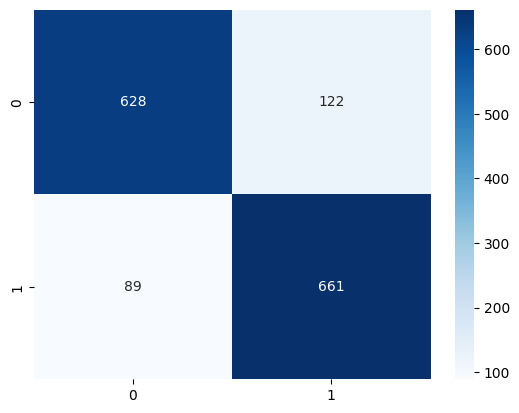

In [ ]:
cm=confusion_matrix(y_test, y_pred)

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.84      0.86       750
           1       0.84      0.88      0.86       750

    accuracy                           0.86      1500
   macro avg       0.86      0.86      0.86      1500
weighted avg       0.86      0.86      0.86      1500



In [ ]:
! curl -L -o flight-price-prediction.zip\
  https://www.kaggle.com/api/v1/datasets/download/shubhambathwal/flight-price-prediction

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 4258k  100 4258k    0     0  9881k      0 --:--:-- --:--:-- --:--:-- 9881k


In [ ]:
!unzip /content/flight-price-prediction.zip

Archive:  /content/flight-price-prediction.zip
  inflating: Clean_Dataset.csv       
  inflating: business.csv            
  inflating: economy.csv             


In [ ]:
df=pd.read_csv('/content/Clean_Dataset.csv')


In [ ]:
X=df.drop(['price','Unnamed: 0','flight'],axis=1)
y=df['price'].copy()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.25, random_state=42
)

In [ ]:
num_features=X.select_dtypes(include=np.number).columns
cat_features=X.select_dtypes(exclude=np.number).columns

In [ ]:
num_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])
cat_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore'))
])
transformer=ColumnTransformer([
    ('num',num_pipeline,num_features),
    ('cat',cat_pipeline,cat_features)
])


In [ ]:
base_model=DecisionTreeRegressor(
    random_state=42,
    max_depth=3
)

ada_model=AdaBoostRegressor(
    estimator=base_model,
    n_estimators=100,
    learning_rate=0.05,
    random_state=42
)
full_pipeline=Pipeline([
    ('transformer',transformer),
    ('model',ada_model)
])


In [ ]:
full_pipeline.fit(X_train,y_train)

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['duration', 'days_left'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['airline', 'source_city', 'departure_time', 'stops', 'arrival_time',
       'destination_city', 'class'],
      dtype='object'))])),
                ('model',
                 AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3,
                                                                   random_state=42),
                                   learning_rate=0.05, n_estimators=100,
                                   random_state=42))])

In [ ]:
full_pipeline.score(X_train,y_train),full_pipeline.score(X_test,y_test)

(0.9349293595734771, 0.9339876250161592)

In [ ]:
r2=r2_score(y_test,full_pipeline.predict(X_test))
r2

0.9339876250161592

In [ ]:
rmse=np.sqrt(mean_squared_error(y_test,full_pipeline.predict(X_test)))
rmse

np.float64(5834.1383019362665)

In [ ]:
gradient_model=GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.5,
    random_state=42,
    max_depth=3,
    subsample=0.8
)
grad_pipeline=Pipeline([
    ('transformer',transformer),
    ('model',gradient_model)
])
grad_pipeline.fit(X_train,y_train)

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['duration', 'days_left'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['airline', 'source_city', 'departure_time', 'stops', 'arrival_time',
       'destination_city', 'class'],
      dtype='object'))])),
                ('model',
                 GradientBoostingRegressor(learning_rate=0.5, random_state=42,
                                           subsample=0.8))])

In [ ]:
grad_pipeline.score(X_train,y_train),grad_pipeline.score(X_test,y_test)

(0.96162935763646, 0.9606134328995826)

In [ ]:
r2=r2_score(y_test,grad_pipeline.predict(X_test))
r2

0.9606134328995826

In [ ]:
histgradboosting_model=HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_depth=8,
    max_bins=255,
    random_state=42
)
num_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])
cat_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))
])
transformer=ColumnTransformer([
    ('num',num_pipeline,num_features),
    ('cat',cat_pipeline,cat_features)
])
hist_pipeline=Pipeline([
    ('transformer',transformer),
    ('model',histgradboosting_model)
])

In [ ]:
hist_pipeline.fit(X_train,y_train)

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['duration', 'days_left'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  Index(['airline', 'source_city', 'departure_time', 'stops', 'arrival_time',
       'destination_city', 'class'],
      dtype='object'))])),
                ('model',
                 HistGradientBoostingRegressor(max_depth=8, random_state=42))])

In [ ]:
hist_pipeline.score(X_train,y_train),hist_pipeline.score(X_test,y_test)

(0.9698607004162064, 0.9683975907642318)

In [ ]:
y_pred=hist_pipeline.predict(X_test)

In [ ]:
r2=r2_score(y_test,y_pred)
r2

0.9683975907642318

In [ ]:
rmse=np.sqrt(mean_squared_error(y_test,y_pred))
rmse

np.float64(4036.6782762226962)

In [ ]:
#XGBooust

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBRegressor

xgb_model=XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    random_state=42,
    max_depth=8,
    subsample=0.8,
    reg_lambda=1
)

xgb_pipeline=Pipeline([
    ('transformer',transformer),
    ('model',xgb_model)
])
xgb_pipeline.fit(X_train,y_train)
y_pred=xgb_pipeline.predict(X_test)
print(r2_score(y_test,y_pred))
print(np.sqrt(mean_squared_error(y_test,y_pred)))

0.9842938184738159
2845.765011380947


In [ ]:
!pip install lightgbm

In [ ]:
from lightgbm import LGBMRegressor
lgbm_model=LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    colsample_bytree=0.8,
    subsample=0.8
)
lgbm_pipeline=Pipeline([
    ('transformer',transformer),
    ('model',lgbm_model)
])
lgbm_pipeline.fit(X_train,y_train)

print(r2_score(y_test,y_pred))
print(np.sqrt(mean_squared_error(y_test,y_pred)))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.055727 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 375
[LightGBM] [Info] Number of data points in the train set: 225114, number of used features: 37
[LightGBM] [Info] Start training from score 20883.980223
0.9842938184738159
2845.765011380947


In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 6.9 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostRegressor
cat_model=CatBoostRegressor(
    n_estimators=500,
    learning_rate=0.05,
    random_seed=42,
    depth=8,
    verbose=0
)
cat_model.fit(
    X_train,y_train,
    cat_features=cat_features.tolist(),
)
y_pred=cat_model.predict(X_test)
print(r2_score(y_test,y_pred))
print(np.sqrt(mean_squared_error(y_test,y_pred)))

0.9723485066968138
3775.9247975619496


In [ ]:
from sklearn.ensemble import VotingRegressor

voting= VotingRegressor([
    ('hist',hist_pipeline),
    ('xgb',xgb_pipeline),
    ('lgbm',lgbm_pipeline)
])
voting_pipeline=Pipeline([
    ('voter',voting)
])
voting_pipeline.fit(X_train,y_train)
y_pred=voting_pipeline.predict(X_test)
print(r2_score(y_test,y_pred))


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014662 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 375
[LightGBM] [Info] Number of data points in the train set: 225114, number of used features: 37
[LightGBM] [Info] Start training from score 20883.980223


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


0.9775109352389578


In [ ]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression

stack=StackingRegressor(
    estimators=[
    ('hist',hist_pipeline),
    ('xgb',xgb_pipeline),
    ('lgbm',lgbm_pipeline)
],final_estimator=LinearRegression()
    )
stack_pipeline=Pipeline([
    ('stack',stack)
])
stack_pipeline.fit(X_train,y_train)
y_pred=stack_pipeline.predict(X_test)
print(r2_score(y_test,y_pred))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014497 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 375
[LightGBM] [Info] Number of data points in the train set: 225114, number of used features: 37
[LightGBM] [Info] Start training from score 20883.980223
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012656 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 375
[LightGBM] [Info] Number of data points in the train set: 180091, number of used features: 37
[LightGBM] [Info] Start training from score 20892.177538


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011192 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 375
[LightGBM] [Info] Number of data points in the train set: 180091, number of used features: 37
[LightGBM] [Info] Start training from score 20867.673060


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011253 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 375
[LightGBM] [Info] Number of data points in the train set: 180091, number of used features: 37
[LightGBM] [Info] Start training from score 20861.187527


...

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.021453 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 375
[LightGBM] [Info] Number of data points in the train set: 180091, number of used features: 37
[LightGBM] [Info] Start training from score 20900.841286


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.027143 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 375
[LightGBM] [Info] Number of data points in the train set: 180092, number of used features: 37
[LightGBM] [Info] Start training from score 20898.021628


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


0.9859767239756971
